# Decoding results: modelling and evaluation

This notebook reports the modelling choices and the honest, held-out evaluation for
Volition, the neuron-set choice decoder, on the IBL Brain-Wide Map cohort. It uses the
same code that produces the shipped model (`src/models`) and reads the result tables
written by `python -m src.models.run_experiments`.

All accuracy numbers are on trials the model never trained on, averaged over three
seeds. Figures are written to `results/figures/`.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parents[0] if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spessine' if False else 'axes.edgecolor': '#444',
                     'axes.grid': True, 'grid.color': '#e6e6e6', 'axes.axisbelow': True})
FIG = ROOT / 'results' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
MODEL = ROOT / 'results' / 'model'
AMBER, AZURE, SLATE = '#d98a1f', '#2f6fd6', '#6b7684'
summary = json.loads((MODEL / 'summary.json').read_text())
print('result tables:', sorted(p.name for p in MODEL.glob('*.csv')))

result tables: ['cross_session.csv', 'pooled_within.csv', 'robustness.csv', 'ssl_ablation.csv']


## 1. The model

Each trial is a set of neurons. A neuron token is its z-scored firing rate in the
pre-movement window plus a learned embedding of its Beryl brain region. A small
transformer encoder with attention pooling reads the unordered set and predicts the
binary choice. Because region ids are shared across sessions, one set of weights reads
sessions with different and non-overlapping neurons.

In [2]:
import torch
from src.models.set_transformer import NeuronSetTransformer
from src.models.serialize import load_model
model, vocab, meta = load_model(ROOT / 'artifacts')
n_params = sum(p.numel() for p in model.parameters())
print(f'shared region vocabulary: {len(vocab)} Beryl regions')
print(f'model parameters: {n_params:,}')
print('held-out metrics:', json.dumps(meta['metrics']['headline_auc'], indent=0))

shared region vocabulary: 65 Beryl regions
model parameters: 125,634
held-out metrics: {
"mean": 0.7483059979801742,
"std": 0.026372065768665083,
"n_seeds": 3
}


D:\projects\brain-decoding\.venv\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


## 2. Shared model versus per-session baselines

The shared transformer is one model across all ten sessions. The per-session logistic regression and random forest are retrained for a single animal.

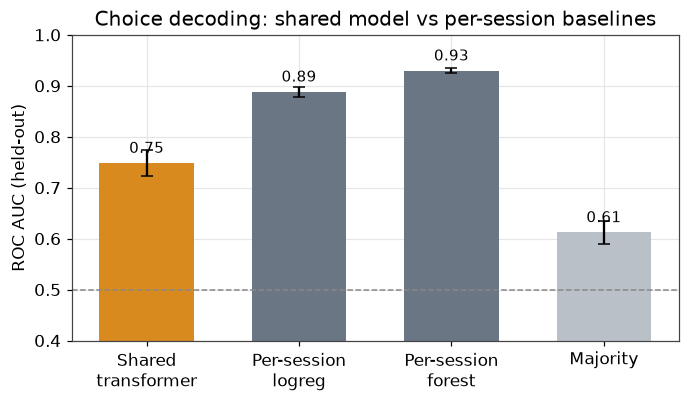

roc_auc        balanced_accuracy           ece       
                   mean    std              mean    std   mean    std
model                                                                
logreg            0.888  0.009             0.821  0.013  0.110  0.011
majority          0.612  0.022             0.580  0.017  0.015  0.004
random_forest     0.930  0.005             0.859  0.005  0.172  0.006
set_transformer   0.748  0.026             0.685  0.017  0.044  0.009

In [3]:
pw = pd.read_csv(MODEL / 'pooled_within.csv')
agg = pw.groupby('model')[['roc_auc','balanced_accuracy','ece']].agg(['mean','std'])
order = ['set_transformer','logreg','random_forest','majority']
labels = {'set_transformer':'Shared\ntransformer','logreg':'Per-session\nlogreg','random_forest':'Per-session\nforest','majority':'Majority'}
auc = [agg.loc[m,('roc_auc','mean')] for m in order]
err = [agg.loc[m,('roc_auc','std')] for m in order]
fig, ax = plt.subplots(figsize=(6.4,3.8))
colors = [AMBER, SLATE, SLATE, '#b9c0c8']
ax.bar([labels[m] for m in order], auc, yerr=err, capsize=4, color=colors, width=0.62)
ax.axhline(0.5, ls='--', color='#888', lw=1); ax.set_ylabel('ROC AUC (held-out)'); ax.set_ylim(0.4,1.0)
for i,v in enumerate(auc): ax.text(i, v+0.02, f'{v:.2f}', ha='center', fontsize=10)
ax.set_title('Choice decoding: shared model vs per-session baselines')
plt.tight_layout(); plt.savefig(FIG/'auc_comparison.png', bbox_inches='tight'); plt.show()
display(agg.round(3))

The shared model decodes well above chance with one set of weights, but the
per-session models are more accurate. Reading a shared, region-level representation
across animals costs accuracy relative to models that exploit each animal's specific
neurons. The shared model is well calibrated (ECE around 0.04).

## 3. Self-supervised pretraining did not help

In [4]:
ab = pd.read_csv(MODEL / 'ssl_ablation.csv')
print(ab.groupby('variant')['roc_auc'].agg(['mean','std']).round(3))
print('\nThe two variants overlap within seed variance, so pretraining is reported as a neutral result.')

           mean    std
variant               
no_ssl    0.759  0.021
with_ssl  0.748  0.026

The two variants overlap within seed variance, so pretraining is reported as a neutral result.


## 4. Transfer to an unseen animal is near chance

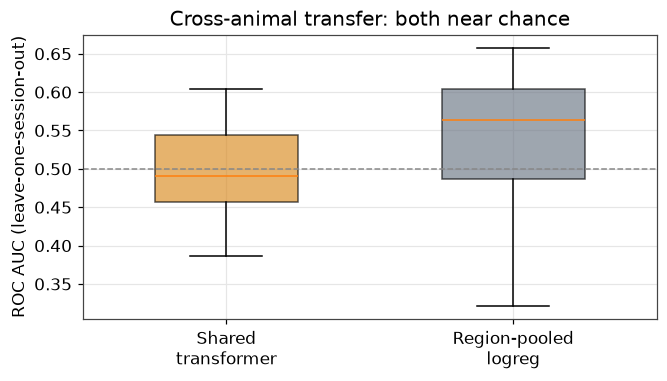

                       mean    std
model                             
region_pooled_logreg  0.541  0.096
set_transformer       0.496  0.064


In [5]:
cs = pd.read_csv(MODEL / 'cross_session.csv')
piv = cs.groupby('model')['roc_auc']
fig, ax = plt.subplots(figsize=(6.2,3.6))
data = [cs[cs.model=='set_transformer'].roc_auc.values, cs[cs.model=='region_pooled_logreg'].roc_auc.values]
bp = ax.boxplot(data, tick_labels=['Shared\ntransformer','Region-pooled\nlogreg'], patch_artist=True, widths=0.5)
for patch, c in zip(bp['boxes'], [AMBER, SLATE]): patch.set_facecolor(c); patch.set_alpha(0.65)
ax.axhline(0.5, ls='--', color='#888', lw=1); ax.set_ylabel('ROC AUC (leave-one-session-out)')
ax.set_title('Cross-animal transfer: both near chance')
plt.tight_layout(); plt.savefig(FIG/'cross_session.png', bbox_inches='tight'); plt.show()
print(piv.agg(['mean','std']).round(3))

## 5. Graceful degradation under neuron and region loss

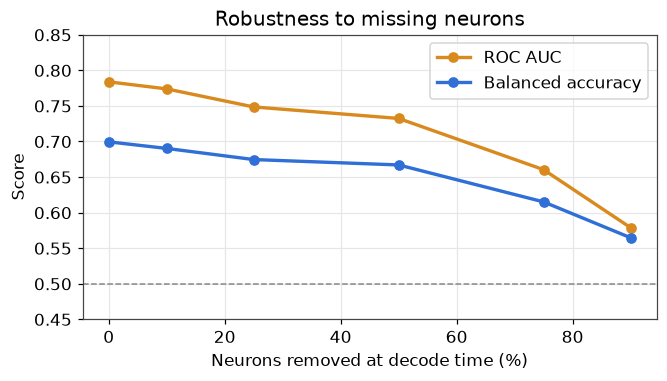

Dropping the largest region per session: AUC 0.700, balanced acc 0.635


In [6]:
rb = pd.read_csv(MODEL / 'robustness.csv')
nd = rb[rb.perturbation=='neuron_dropout']
fig, ax = plt.subplots(figsize=(6.2,3.6))
ax.plot(nd.level*100, nd.roc_auc, '-o', color=AMBER, lw=2.2, label='ROC AUC')
ax.plot(nd.level*100, nd.balanced_accuracy, '-o', color=AZURE, lw=2.2, label='Balanced accuracy')
ax.axhline(0.5, ls='--', color='#888', lw=1)
ax.set_xlabel('Neurons removed at decode time (%)'); ax.set_ylabel('Score'); ax.set_ylim(0.45,0.85)
ax.legend(); ax.set_title('Robustness to missing neurons')
plt.tight_layout(); plt.savefig(FIG/'robustness.png', bbox_inches='tight'); plt.show()
top = rb[rb.perturbation=='drop_top_region']
print(f"Dropping the largest region per session: AUC {top.roc_auc.values[0]:.3f}, balanced acc {top.balanced_accuracy.values[0]:.3f}")

## 6. Interpretability: attention over regions for one trial

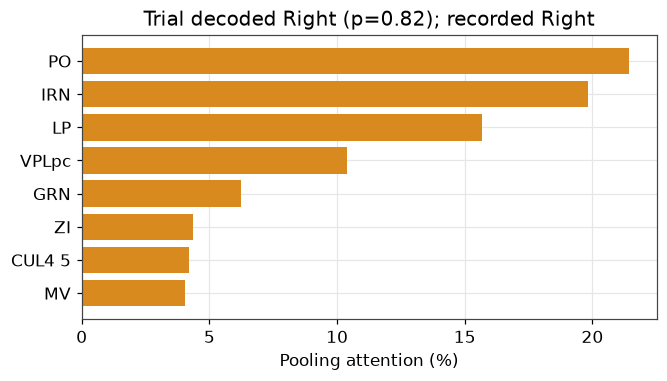

In [7]:
from src.models.data import load_sessions
sessions, _ = load_sessions()
s = sessions[0]; ti = 0
import numpy as np
# pad and run the shipped model with attention
from src.models.serialize import MAX_NEURONS
import torch
rates = torch.zeros(1, MAX_NEURONS); ids = torch.zeros(1, MAX_NEURONS, dtype=torch.long)
pm = torch.ones(1, MAX_NEURONS, dtype=torch.bool)
n = s.n_neurons
rates[0,:n] = torch.tensor(s.X[ti]); ids[0,:n] = torch.tensor(s.region_ids); pm[0,:n] = False
with torch.no_grad():
    logit, attn = model.forward_with_attention(rates, ids, pm)
prob = torch.sigmoid(logit).item(); a = attn[0,:n].numpy()
byreg = {}
for r,w in zip(s.regions, a): byreg[r] = byreg.get(r,0)+w
topreg = sorted(byreg.items(), key=lambda kv:-kv[1])[:8]
fig, ax = plt.subplots(figsize=(6.2,3.6))
names=[r for r,_ in topreg][::-1]; vals=[w*100 for _,w in topreg][::-1]
ax.barh(names, vals, color=AMBER); ax.set_xlabel('Pooling attention (%)')
ax.set_title(f'Trial decoded {"Right" if prob>=0.5 else "Left"} (p={prob:.2f}); recorded {"Right" if s.y[ti]==1 else "Left"}')
plt.tight_layout(); plt.savefig(FIG/'attention_example.png', bbox_inches='tight'); plt.show()

## 7. Honest summary

- A single shared neuron-set transformer decodes pre-movement choice at ROC AUC
  0.75, well above chance and well calibrated, across ten animals.
- Per-session linear and forest decoders are more accurate (AUC 0.89 and 0.93). The
  shared, region-level representation is the cost of one model that spans animals and
  reads any neuron set.
- Self-supervised pretraining gave no reliable improvement on this dataset.
- Transfer to an unseen animal is near chance for every method tested.
- The decoder degrades gracefully as neurons are removed, and its attention gives a
  faithful per-region account of each prediction.